# Deep Learning Skill Lab - COCO Traffic Dataset Exploration

## 0. Setup – install dependencies

In [1]:
%pip install -q numpy pandas matplotlib seaborn pillow

## 1. Imports

In [2]:
import os
import glob
import random
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from IPython.display import display

sns.set_theme(style="whitegrid")
random.seed(42)

print("=" * 65)
print("       COCO TRAFFIC DATASET EXPLORATION")
print("=" * 65)

       COCO TRAFFIC DATASET EXPLORATION


## 2. Download and extract COCO128 (automatic)

In [3]:
DATASET_URLS = [
    "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip",
    "https://ultralytics.com/assets/coco128.zip",
]
zip_file = "coco128.zip"
dataset_path = "traffic_coco"

if not os.path.exists(zip_file):
    for url in DATASET_URLS:
        try:
            print("Downloading COCO128 from:", url)
            urllib.request.urlretrieve(url, zip_file)
            break
        except Exception as e:
            print("  Failed:", e)
    else:
        raise RuntimeError("Could not download COCO128. Check your internet connection.")

os.makedirs(dataset_path, exist_ok=True)
with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(dataset_path)

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


## 3. Locate images and YOLO label files

In [4]:
image_files = glob.glob(dataset_path + "/**/images/**/*.jpg", recursive=True)
if not image_files:
    image_files = glob.glob(dataset_path + "/**/*.jpg", recursive=True)

label_files = glob.glob(dataset_path + "/**/labels/**/*.txt", recursive=True)

if not image_files:
    raise FileNotFoundError("No images found in ZIP!")
if not label_files:
    raise FileNotFoundError("No YOLO annotation files found!")

label_lookup = {os.path.splitext(os.path.basename(p))[0]: p for p in label_files}

print("Total photographs:", len(image_files))
print("Total annotation files:", len(label_files))

Total photographs: 128
Total annotation files: 128


## 4. COCO class names and traffic categories

In [5]:
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush",
]

vehicle_ids = [1, 2, 3, 5, 7]   # bicycle, car, motorcycle, bus, truck
road_ids = [9, 11, 12]          # traffic light, stop sign, parking meter
traffic_ids = vehicle_ids + road_ids

## 5. Select images that contain traffic objects

In [6]:
traffic_records = []
category_counts = Counter()

for image_path in image_files:
    name = os.path.splitext(os.path.basename(image_path))[0]
    label_path = label_lookup.get(name)
    if not label_path:
        continue

    objects = []
    with open(label_path, "r") as f:
        for line in f:
            values = line.split()
            if len(values) < 5:
                continue
            values = list(map(float, values))
            cid = int(values[0])
            if cid not in traffic_ids:
                continue
            xc, yc, w, h = values[1:5]
            objects.append({"id": cid, "name": class_names[cid],
                            "xc": xc, "yc": yc, "w": w, "h": h})

    # keep only images containing at least one real vehicle
    if any(o["id"] in vehicle_ids for o in objects):
        traffic_records.append({"path": image_path, "objects": objects})
        for o in objects:
            category_counts[o["name"]] += 1

print("TRAFFIC IMAGES FOUND:", len(traffic_records))

if not traffic_records:
    raise ValueError("No vehicle images found. Please check the dataset download.")

TRAFFIC IMAGES FOUND: 22


## 6. Real traffic photographs with bounding boxes

REAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES


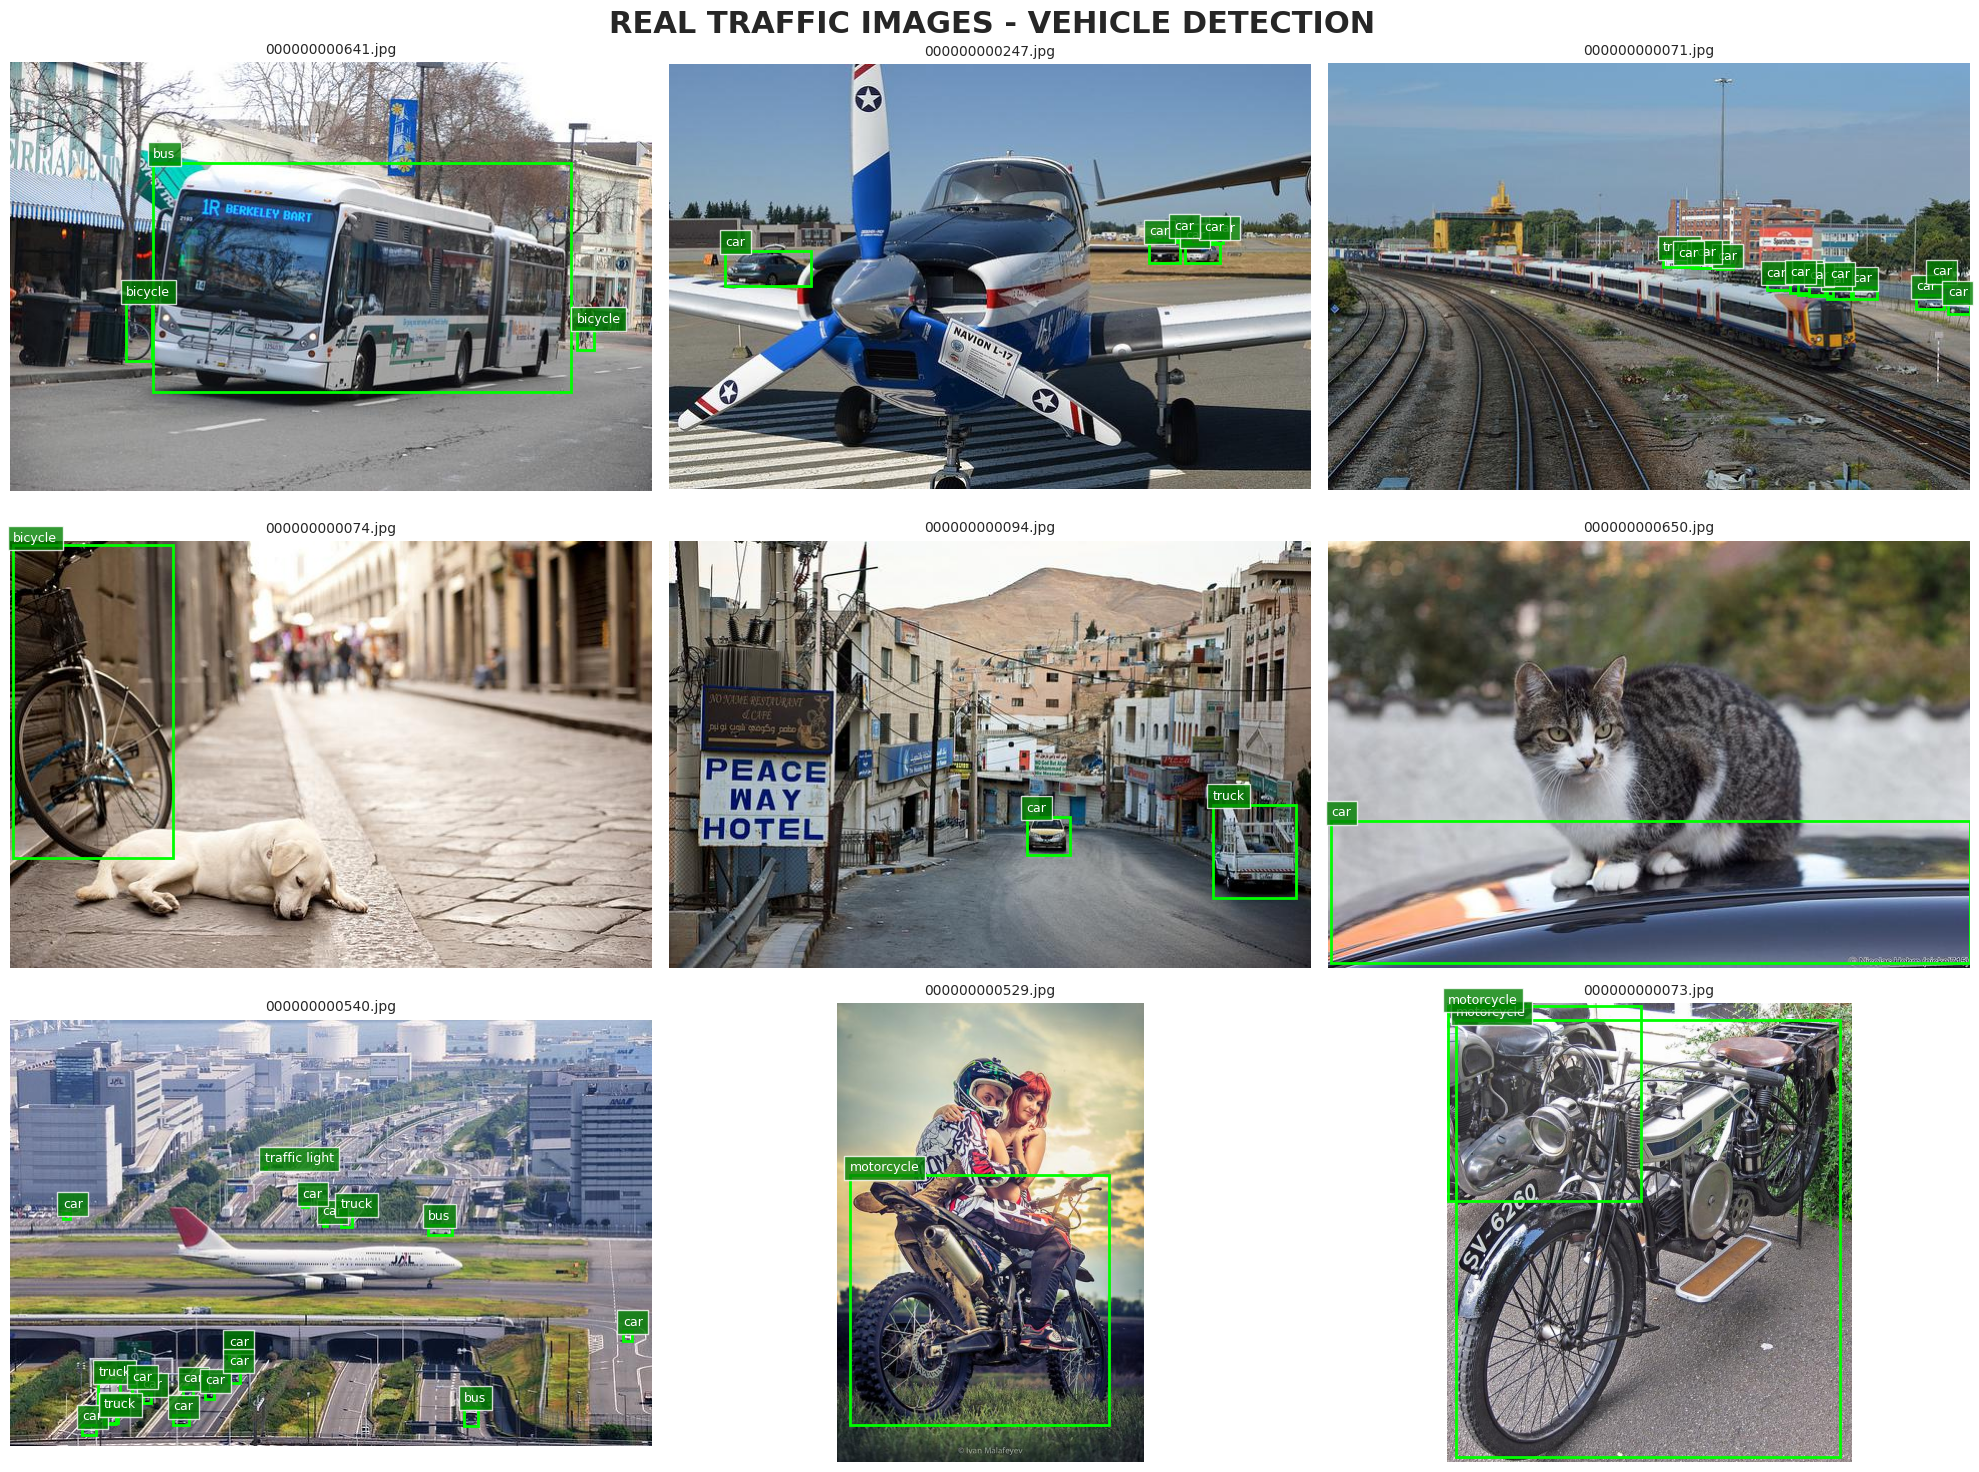

In [7]:
print("REAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES")

sample = random.sample(traffic_records, min(9, len(traffic_records)))

fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten()

for ax, record in zip(axes, sample):
    img = Image.open(record["path"]).convert("RGB")
    width, height = img.size
    ax.imshow(img)

    for obj in record["objects"]:
        bw, bh = obj["w"] * width, obj["h"] * height
        x = obj["xc"] * width - bw / 2
        y = obj["yc"] * height - bh / 2

        ax.add_patch(patches.Rectangle((x, y), bw, bh, linewidth=2,
                                       edgecolor="lime", facecolor="none"))
        ax.text(x, max(0, y - 5), obj["name"], color="white", fontsize=9,
                bbox=dict(facecolor="green", alpha=0.8))

    ax.set_title(os.path.basename(record["path"]), fontsize=10)
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.suptitle("REAL TRAFFIC IMAGES - VEHICLE DETECTION", fontsize=22, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Category distribution (bar chart)

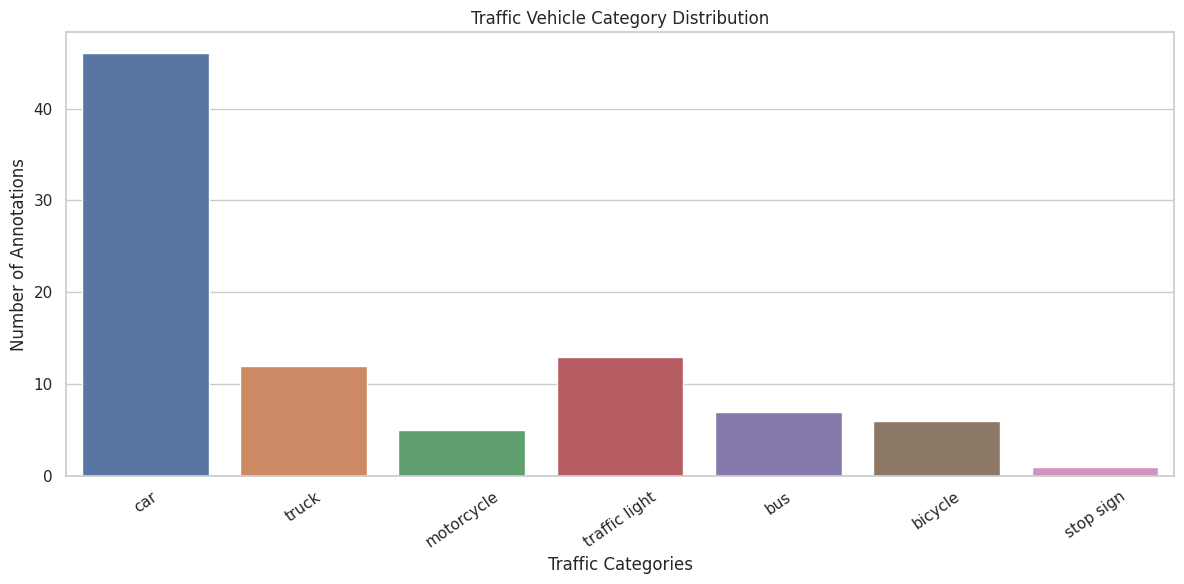

In [8]:
names = list(category_counts.keys())
counts = list(category_counts.values())

plt.figure(figsize=(12, 6))
sns.barplot(x=names, y=counts, hue=names, legend=False)
plt.title("Traffic Vehicle Category Distribution")
plt.xlabel("Traffic Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 8. Category distribution (pie chart)

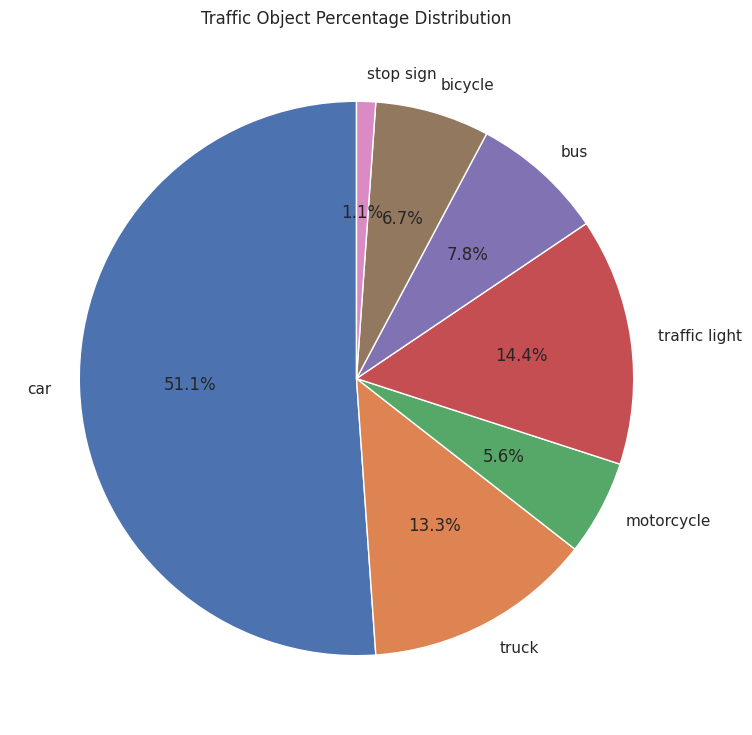

In [9]:
plt.figure(figsize=(9, 9))
plt.pie(counts, labels=names, autopct="%1.1f%%", startangle=90)
plt.title("Traffic Object Percentage Distribution")
plt.show()

## 9. Bounding-box size analysis

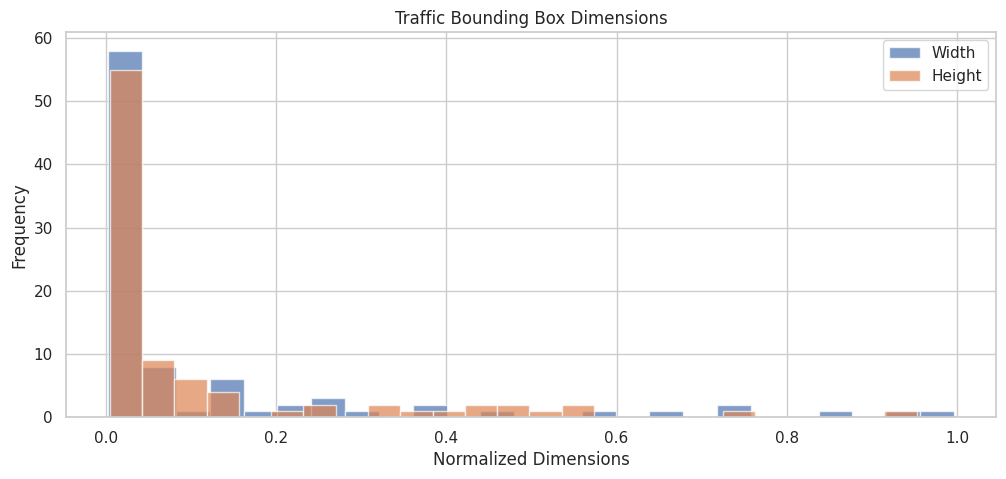

In [10]:
widths = [o["w"] for r in traffic_records for o in r["objects"]]
heights = [o["h"] for r in traffic_records for o in r["objects"]]

plt.figure(figsize=(12, 5))
plt.hist(widths, bins=25, alpha=0.7, label="Width")
plt.hist(heights, bins=25, alpha=0.7, label="Height")
plt.title("Traffic Bounding Box Dimensions")
plt.xlabel("Normalized Dimensions")
plt.ylabel("Frequency")
plt.legend()
plt.show()

## 10. Objects per image

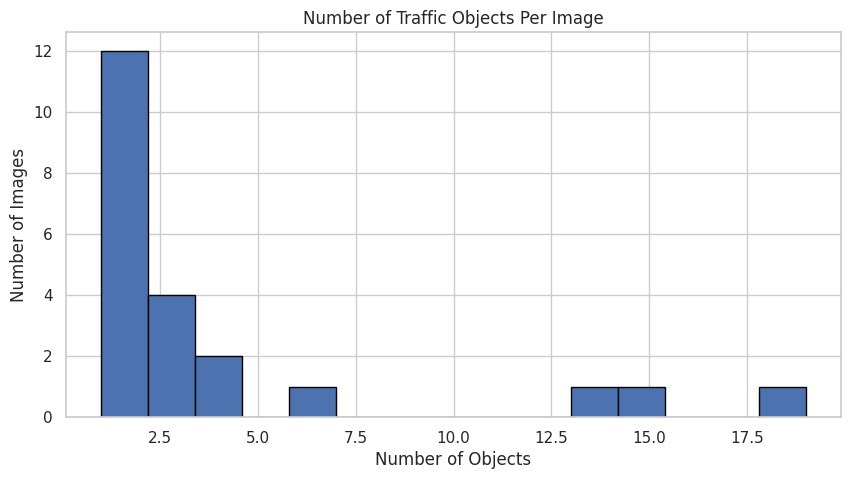

In [11]:
objects_per_image = [len(r["objects"]) for r in traffic_records]

plt.figure(figsize=(10, 5))
plt.hist(objects_per_image, bins=15, edgecolor="black")
plt.title("Number of Traffic Objects Per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")
plt.show()

## 11. Annotation table

In [12]:
rows = [
    {
        "Image": os.path.basename(r["path"]),
        "Category": o["name"],
        "X Center": round(o["xc"], 4),
        "Y Center": round(o["yc"], 4),
        "Width": round(o["w"], 4),
        "Height": round(o["h"], 4),
    }
    for r in traffic_records
    for o in r["objects"]
]

df = pd.DataFrame(rows)
print("ANNOTATION TABLE")
display(df.head(20))

ANNOTATION TABLE


,Image,Category,X Center,Y Center,Width,Height
0,000000000071.jpg,car,0.7526,0.5258,0.0434,0.0332
1,000000000071.jpg,car,0.8357,0.5385,0.0380,0.0282
2,000000000071.jpg,car,0.7009,0.5215,0.0364,0.0202
3,000000000071.jpg,car,0.9374,0.5598,0.0424,0.0336
4,000000000071.jpg,car,0.7950,0.5388,0.0368,0.0262
5,000000000071.jpg,car,0.9535,0.5149,0.0261,0.0127
6,000000000071.jpg,truck,0.5397,0.4641,0.0373,0.0239
7,000000000071.jpg,truck,0.5852,0.4714,0.0380,0.0166
8,000000000071.jpg,car,0.9826,0.5724,0.0349,0.0300
9,000000000071.jpg,car,0.7674,0.5313,0.0374,0.0297


## 12. Final report

In [13]:
print("=" * 60)
print("       FINAL TRAFFIC DATASET REPORT")
print("=" * 60)

print("Total Dataset Images :", len(image_files))
print("Traffic Images       :", len(traffic_records))
print("Traffic Categories   :", len(names))
print("Total Annotations    :", len(df))

print("\nCATEGORY COUNTS")
for name, count in category_counts.items():
    print(f"  {name} : {count}")

print("\nAverage Objects Per Image:", round(np.mean(objects_per_image), 2))
print("Average Box Width        :", round(np.mean(widths), 4))
print("Average Box Height       :", round(np.mean(heights), 4))

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 60)

       FINAL TRAFFIC DATASET REPORT
Total Dataset Images : 128
Traffic Images       : 22
Traffic Categories   : 7
Total Annotations    : 90

CATEGORY COUNTS
  car : 46
  truck : 12
  motorcycle : 5
  traffic light : 13
  bus : 7
  bicycle : 6
  stop sign : 1

Average Objects Per Image: 4.09
Average Box Width        : 0.1239
Average Box Height       : 0.1124

EXPERIMENT COMPLETED SUCCESSFULLY!
